# 03 · A Chatbot with Claude + LLM Workflows  🟢 Beginner

Now nodes call Claude. You will learn:
1. `MessagesState` and the `add_messages` reducer
2. A one-node chatbot graph
3. Custom state on top of messages
4. **Prompt chaining** workflow with a quality gate (LLM + conditional edge)

In [1]:
from helpers import get_llm, show_graph, print_messages

llm = get_llm()   # ChatAnthropic -> Claude, key read from CLAUDE_KEY in .env

## 1. The `add_messages` reducer

Chat apps store a list of messages. `add_messages` is a smart reducer:
it **appends** new messages, **replaces** a message with the same `id`, and converts tuples/dicts into message objects.

In [2]:
from langgraph.graph import add_messages
from langchain_core.messages import HumanMessage, AIMessage

history = [HumanMessage("Hi", id="1")]
history = add_messages(history, [AIMessage("Hello! How can I help?", id="2")])   # append
history = add_messages(history, [("user", "Tell me a joke")])                      # tuple -> HumanMessage
history = add_messages(history, [AIMessage("Hey there! How can I help?", id="2")]) # same id -> replace
for m in history:
    print(m.type, "|", m.content)

human | Hi
ai | Hey there! How can I help?
human | Tell me a joke


`MessagesState` is a ready-made state: `{"messages": Annotated[list[AnyMessage], add_messages]}`.

## 2. One-node chatbot

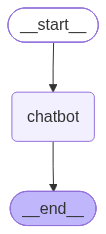

In [3]:
from langgraph.graph import StateGraph, MessagesState, START, END

def chatbot(state: MessagesState):
    reply = llm.invoke(state["messages"])
    return {"messages": [reply]}                 # appended thanks to add_messages

builder = StateGraph(MessagesState)
builder.add_node("chatbot", chatbot)
builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)
chat_graph = builder.compile()
show_graph(chat_graph)

In [4]:
result = chat_graph.invoke({"messages": [("user", "Hi! I'm learning LangGraph. Give me one tip.")]})
print_messages(result["messages"])

===== HUMAN =====
Hi! I'm learning LangGraph. Give me one tip.
===== AI =====
**Tip: Understand reducers in your state schema. They control how node outputs get merged.**

By default, when a node returns a value for a state key, it **overwrites** the existing value. This catches many beginners off guard, especially with message lists.

```python
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages
import operator

class State(TypedDict):
    # Without a reducer: each update REPLACES the value
    current_step: str

    # With add_messages: new messages are APPENDED (and deduped by ID)
    messages: Annotated[list, add_messages]

    # With operator.add: lists are concatenated
    logs: Annotated[list[str], operator.add]
```

Now a node only needs to return what changed:

```python
def my_node(state: State):
    return {"logs": ["my_node ran"]}  # appended, not replaced
```

**Why it matters:**
- Nodes return *partial updates*, not the full state.
- W

### Multi-turn (the manual way)

The graph is stateless between calls, so *we* must pass the history back in.
(Notebook 05 makes this automatic with a **checkpointer**.)

In [5]:
history = result["messages"] + [("user", "What did I say I was learning?")]
result = chat_graph.invoke({"messages": history})
print(result["messages"][-1].text)

You said you're learning **LangGraph**.


## 3. Custom state: messages + your own fields

Extend `MessagesState` to carry extra data, e.g. a persona and a turn counter.
The system prompt is added inside the node, so it is never stored in history.

In [6]:
from langchain_core.messages import SystemMessage

class PersonaState(MessagesState):
    persona: str
    turns: int

def persona_bot(state: PersonaState):
    system = SystemMessage(f"You are {state['persona']}. Reply in at most 2 sentences.")
    reply = llm.invoke([system] + state["messages"])
    return {"messages": [reply], "turns": state.get("turns", 0) + 1}

b = StateGraph(PersonaState)
b.add_node("bot", persona_bot)
b.add_edge(START, "bot"); b.add_edge("bot", END)
persona_graph = b.compile()

for persona in ["a pirate captain", "a calm yoga teacher"]:
    out = persona_graph.invoke({"messages": [("user", "How do I fix a bug in my code?")], "persona": persona})
    print(f"[{persona}] {out['messages'][-1].text}\n")

[a pirate captain] Arr, first ye must reproduce the cursed bug reliably, then hunt it down with print statements or a debugger, checkin' yer variables at each step 'til ye spot where the values go astray from what ye expected. Once ye've found the scallywag, fix it, test it again, and write a test so the bilge rat never sneaks back aboard!



[a calm yoga teacher] Take a deep breath and read the error message slowly, then reproduce the bug and add print statements or use a debugger to trace exactly where your code's behavior differs from what you expect. Change one small thing at a time and test after each change, and if you feel stuck, step away for a moment, because clarity often arrives when the mind is at rest.



## 4. Workflow pattern: prompt chaining with a gate

Not every LLM app is an "agent". Often a **fixed workflow** is more reliable:

`generate tagline → (gate: is it short enough?) → improve → polish`

The gate is plain Python: cheap, deterministic, testable.

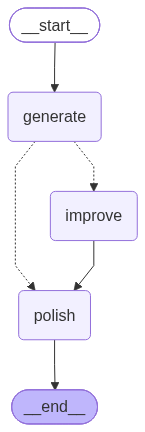

In [7]:
from typing import TypedDict, Literal

class TaglineState(TypedDict):
    product: str
    tagline: str
    final: str

def generate(state: TaglineState):
    t = llm.invoke(f"Write ONE descriptive marketing tagline (about 15 words) for: {state['product']}. Output only the tagline.").text
    return {"tagline": t.strip()}

def gate(state: TaglineState) -> Literal["improve", "polish"]:
    words = len(state["tagline"].split())
    print(f"gate: {words} words -> {'improve' if words > 8 else 'polish'}")
    return "improve" if words > 8 else "polish"

def improve(state: TaglineState):
    t = llm.invoke(f"Shorten this tagline to at most 8 words, keep it punchy. Output only the tagline:\n{state['tagline']}").text
    return {"tagline": t.strip()}

def polish(state: TaglineState):
    t = llm.invoke(f"Add one fitting emoji to this tagline. Output only the result:\n{state['tagline']}").text
    return {"final": t.strip()}

b = StateGraph(TaglineState)
for fn in (generate, improve, polish):
    b.add_node(fn)
b.add_edge(START, "generate")
b.add_conditional_edges("generate", gate)
b.add_edge("improve", "polish")
b.add_edge("polish", END)
chain = b.compile()
show_graph(chain)

In [8]:
out = chain.invoke({"product": "a reusable smart water bottle that tracks hydration and glows to remind you to drink"})
print("tagline:", out["tagline"])
print("final  :", out["final"])

gate: 15 words -> improve


tagline: Tracks every sip. Glows when it's time.
final  : Tracks every sip. Glows when it's time. 💧


## ✅ Recap
* `MessagesState` + `add_messages` = the standard chat state.
* A node can call Claude and return `{"messages": [reply]}`.
* Put **system prompts inside nodes**; keep state for real conversation data.
* **Workflows** (fixed paths + gates) vs **agents** (LLM decides the path) — next notebook builds an agent.